# 業種成分を `comp_ew` に加える

`01_within_across` の結果から、`comp_ew` を業種内に変換するのではなく、素の `comp_ew` に効いていた業種成分を明示的に加える。

**候補**（01 で見つけたもの）

| シグナル | 定義（業種 = GICS 産業グループ、5 銘柄未満はセクター） | 01 での根拠 |
| --- | --- | --- |
| `IMOM1` | mom1（直近 1 か月リターン）の業種間成分 = 業種の 1 か月リターンの中央値 | 業種間 +9.8%（t 3.0） |
| `IREV` | リビジョン（rev1p, rev1r, rev3p, rev3r の Blom 平均）の業種間成分 | rev3r 業種間 t 2.4 |
| `IMOM` | `IMOM1` と `IREV` の等ウェイト | 業種モメンタム（OOS t 2.3） |
| `ITREND_SREV` | `IMOM1` + 業種内の 1 か月リバーサル（−mom1 の業種内成分）。業種で順張り × 銘柄で逆張り | mom1 業種内 −6.8%（t −2.2） |
| `SREV` | 業種内の 1 か月リバーサル単体（−mom1 の業種内成分）。`ITREND_SREV` の切り分け用 | 同上 |
| `IVAL` | Stock Value（bp_est, bp_act）の業種間成分 = セクターの割安度 | 業種間 t 1.7 / 業種内 0.3 |
| `VAL_RAW` | Stock Value の素のまま（対照: 業種間として扱う意味があるか） | 素のまま t 0.6 |

**合成**: $\alpha = \mathrm{blom}\big((1-\lambda)\, z(\text{comp\_ew}) + \lambda\, z(\text{シグナル})\big)$、$\lambda = 0.2$（シグナルが無い銘柄は 0）。
§3 で $\lambda = 0.1, 0.3$ も見る。

**データマイニングへの注意**: 候補は 01 の全期間の結果から選んだので、全期間の成績は楽観的になる。$\lambda$ を固定し、
2017 年まで（IS）と 2018 年以降（OOS）の両方で `comp_ew` を上回るかで判断する。1 か月のシグナルは回転率を上げるので、税控除後も重視する。

**規約**: Q5（等ウェイトの BM 超過）→ IC → Q5−Q1。drtn と srtn。税は信託扱い・売買コスト 15/25bp・バーンイン 12 か月、BM は MSCI India。スコアは 2008-01〜2026-06。

In [1]:
import warnings

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from alphaeval import (
    InputStore,
    compute_alpha_report,
    india_tax_schedule,
    plot_cumulative,
    summary_table,
)
from alphaeval.industry import (
    blom,
    industry_decompose,
    industry_labels,
    quantile_excess,
)

warnings.simplefilter("ignore", RuntimeWarning)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12
LAMBDA = 0.2
WINDOW = ("2018-05-01", "2019-08-31")
IS, OOS = ("2009-01-01", "2017-12-31"), ("2018-01-01", "2026-12-31")  # リターンの月

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
gics = store.alpha("attributes/gics", START, END).reindex(
    index=univ.index, columns=univ.columns
)
lab = industry_labels(gics, "industry_group", universe=univ, min_size=5)
returns = {
    kind: store.returns(RISK_MODEL, col, START, 202607)
    for kind, col in RETURN_KINDS.items()
}
fwd = returns["drtn"].reindex(columns=univ.columns).shift(-1).reindex(univ.index)
schedule = india_tax_schedule(FPI_TYPE)


def load(path: str) -> pd.DataFrame:
    return (
        store.alpha(path, START, END)
        .reindex(index=univ.index, columns=univ.columns)
        .where(univ.notna())
    )


def mean_blom(frames: list[pd.DataFrame]) -> pd.DataFrame:
    avg = pd.concat([blom(f) for f in frames]).groupby(level=0).mean()
    return blom(avg.reindex(univ.index).where(univ.notna()))


comp = load("composite/comp_ew")
mom1 = load("core/mom1")
rev = mean_blom([load(f"core/{f}") for f in ["rev1p", "rev1r", "rev3p", "rev3r"]])
val = mean_blom([load(f"core/{f}") for f in ["bp_est", "bp_act"]])

a_mom1, w_mom1 = industry_decompose(mom1, lab)
a_rev, _ = industry_decompose(rev, lab)
a_val, _ = industry_decompose(val, lab)
signals = {
    "IMOM1": blom(a_mom1),
    "IREV": blom(a_rev),
    "IMOM": mean_blom([a_mom1, a_rev]),
    "ITREND_SREV": mean_blom([a_mom1, -w_mom1]),
    "SREV": blom(-w_mom1),
    "IVAL": blom(a_val),
    "VAL_RAW": val,
}
print({n: f"{int(s.notna().sum(axis=1).mean())} 銘柄/月" for n, s in signals.items()})

{'IMOM1': '373 銘柄/月', 'IREV': '336 銘柄/月', 'IMOM': '373 銘柄/月', 'ITREND_SREV': '373 銘柄/月', 'SREV': '373 銘柄/月', 'IVAL': '374 銘柄/月', 'VAL_RAW': '374 銘柄/月'}


## 1. シグナル単体と `comp_ew` との関係

各シグナル単体の分位超過（等ウェイトユニバース対比、drtn）と、`comp_ew` との順位相関（月次平均）。

In [2]:
def tstat(s: pd.Series) -> float:
    s = s.dropna()
    return float(s.mean() / s.std() * np.sqrt(len(s))) if len(s) > 2 else np.nan


def row_rank_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    m = a.notna() & b.notna()
    ra, rb = a.where(m).rank(axis=1), b.where(m).rank(axis=1)
    ra, rb = ra.sub(ra.mean(axis=1), axis=0), rb.sub(rb.mean(axis=1), axis=0)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))


rows = {}
for n, s in {"comp_ew": comp, **signals}.items():
    q = quantile_excess(s, fwd, N_QUANTILES)["spread"]
    q.index = q.index + pd.offsets.MonthEnd(1)  # リターンの月に合わせる
    rows[n] = {
        "Q5−Q1 年率": q.mean() * 12,
        "t": tstat(q),
        "IS 年率": q.loc[IS[0] : IS[1]].mean() * 12,
        "IS t": tstat(q.loc[IS[0] : IS[1]]),
        "OOS 年率": q.loc[OOS[0] : OOS[1]].mean() * 12,
        "OOS t": tstat(q.loc[OOS[0] : OOS[1]]),
        "comp_ew との相関": float(row_rank_corr(s, comp).mean()),
    }
display(pd.DataFrame(rows).T.round(3))

,Q5−Q1 年率,t,IS 年率,IS t,OOS 年率,OOS t,comp_ew との相関
comp_ew,0.178,4.739,0.200,3.241,0.167,3.828,1.000
IMOM1,0.098,2.988,0.141,3.011,0.037,0.860,0.026
IREV,0.063,1.883,0.052,1.031,0.070,1.584,0.124
IMOM,0.127,4.072,0.157,3.493,0.091,2.185,0.089
ITREND_SREV,0.103,4.440,0.112,3.709,0.081,2.193,-0.045
SREV,0.068,2.202,0.027,0.610,0.093,2.549,-0.093
IVAL,0.063,1.647,0.041,0.641,0.060,1.433,-0.025
VAL_RAW,0.027,0.551,0.024,0.292,0.019,0.325,-0.225


## 2. `comp_ew` に加えたときの評価（$\lambda = 0.2$）

In [3]:
def overlay(sig: pd.DataFrame, lam: float) -> pd.DataFrame:
    zc = blom(comp)
    return blom(
        ((1 - lam) * zc + lam * sig.reindex_like(zc).fillna(0.0)).where(comp.notna())
    )


def report(name: str, score: pd.DataFrame):
    return compute_alpha_report(
        name,
        score,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        tax_schedule=schedule,
        cost_buy=COST_BUY,
        cost_sell=COST_SELL,
        burn_in=BURN_IN,
        tax_kind="drtn",
    )


reports = {"comp_ew": report("comp_ew", comp)}
for n, s in signals.items():
    reports[f"+{n}"] = report(f"+{n}", overlay(s, LAMBDA))

first = reports["comp_ew"]
tbl = summary_table(reports)
q5, sp, at = (
    first.label("ew_excess"),
    first.label("spread"),
    first.label("after_tax_excess"),
)
cols = [q5, q5 + " IR", "IC", "ICIR", "IC t", sp, sp + " IR"]
for kind in ["drtn", "srtn"]:
    print(
        f"{kind}（{'配当込みトータルリターン' if kind == 'drtn' else '固有リターン'}）"
    )
    display(tbl[kind][cols].round(3))
print("税控除後（drtn）、回転率、コスト・税のドラッグ")
display(
    pd.concat(
        [
            tbl["drtn"][[at, at + " IR"]],
            tbl["共通"][["回転率 EW", "コストドラッグ", "税ドラッグ", "短期比率"]],
        ],
        axis=1,
    ).round(3)
)

drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.130,1.165,0.065,0.482,6.982,0.176,1.152
+IMOM1,0.133,1.193,0.068,0.487,7.063,0.189,1.181
+IREV,0.133,1.249,0.068,0.476,6.891,0.176,1.076
+IMOM,0.132,1.208,0.070,0.491,7.119,0.193,1.188
+ITREND_SREV,0.139,1.245,0.073,0.556,8.063,0.210,1.401
+SREV,0.135,1.218,0.071,0.582,8.434,0.197,1.404
+IVAL,0.136,1.173,0.063,0.540,7.831,0.186,1.393
+VAL_RAW,0.130,1.110,0.062,0.569,8.246,0.182,1.444


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.101,1.009,0.039,0.380,5.501,0.117,1.071
+IMOM1,0.103,1.022,0.042,0.391,5.664,0.129,1.145
+IREV,0.104,1.087,0.041,0.378,5.472,0.118,1.033
+IMOM,0.102,1.035,0.043,0.393,5.697,0.128,1.125
+ITREND_SREV,0.111,1.108,0.047,0.469,6.800,0.154,1.458
+SREV,0.109,1.105,0.047,0.494,7.153,0.146,1.471
+IVAL,0.102,1.002,0.038,0.395,5.719,0.124,1.255
+VAL_RAW,0.096,0.955,0.035,0.386,5.590,0.114,1.180


税控除後（drtn）、回転率、コスト・税のドラッグ


指標,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,回転率 EW,コストドラッグ,税ドラッグ,短期比率
comp_ew,0.085,0.790,4.022,0.017,0.028,0.809
+IMOM1,0.083,0.778,4.524,0.019,0.030,0.852
+IREV,0.085,0.836,4.188,0.017,0.029,0.821
+IMOM,0.083,0.798,4.361,0.018,0.029,0.839
+ITREND_SREV,0.085,0.806,4.856,0.020,0.033,0.880
+SREV,0.081,0.783,4.952,0.020,0.032,0.890
+IVAL,0.089,0.810,4.039,0.017,0.028,0.809
+VAL_RAW,0.083,0.743,4.184,0.017,0.028,0.803


### IS（2009〜2017 年）と OOS（2018 年以降）での `comp_ew` との差

月次差の平均（年率、IC は平均）と t 値。両方の期間でプラスなら、全期間の結果がたまたまではない根拠になる。

In [4]:
def diff_table(reports: dict, base: str = "comp_ew") -> pd.DataFrame:
    rows = {}
    for n, rep in reports.items():
        if n == base:
            continue
        r = {}
        for metric, label, scale in [
            ("ew_excess", "Q5 超過", 12),
            ("ic", "IC", 1),
            ("spread", "Q5−Q1", 12),
            ("after_tax_excess", "税後 Q5", 12),
        ]:
            d = (
                rep.series[metric]["drtn"] - reports[base].series[metric]["drtn"]
            ).dropna()
            for p, (a, b) in {"IS": IS, "OOS": OOS}.items():
                x = d.loc[a:b]
                r[(label, f"{p} 差")] = x.mean() * scale
                r[(label, f"{p} t")] = tstat(x)
        rows[n] = r
    return pd.DataFrame(rows).T


display(diff_table(reports).round(3))

P = {
    "2009–2017": ("2009-01-01", "2017-12-31"),
    "窓 2018/05–2019/08": WINDOW,
    "2020/04–12": ("2020-04-01", "2020-12-31"),
    "2021–2026": ("2021-01-01", "2026-12-31"),
}
rows = {}
for n, rep in reports.items():
    rows[n] = {
        (p, "Q5 超過"): rep.series["ew_excess"]["drtn"].loc[a:b].mean() * 12
        for p, (a, b) in P.items()
    }
print("期間別の Q5 超過（drtn、年率）")
display(pd.DataFrame(rows).T.round(3))

Q5 超過                          IC                       Q5−Q1                       税後 Q5                     
               IS 差   IS t  OOS 差  OOS t   IS 差   IS t  OOS 差  OOS t   IS 差   IS t  OOS 差  OOS t   IS 差   IS t  OOS 差  OOS t
+IMOM1        0.004  0.515  0.001  0.099  0.007  2.562  0.001  0.208  0.023  1.879  0.003  0.236 -0.001 -0.102 -0.003 -0.365
+IREV         0.003  0.309  0.003  0.353  0.004  1.803  0.002  0.888  0.001  0.090 -0.001 -0.053  0.000  0.026  0.001  0.111
+IMOM         0.004  0.424 -0.000 -0.058  0.008  3.145  0.003  1.197  0.029  2.233  0.005  0.379 -0.000 -0.015 -0.003 -0.369
+ITREND_SREV  0.012  1.623  0.006  0.705  0.009  4.799  0.006  3.325  0.041  3.236  0.026  2.211  0.002  0.326 -0.002 -0.186
+SREV         0.004  0.481  0.005  0.619  0.005  1.852  0.008  3.698  0.021  1.247  0.021  1.609 -0.004 -0.500 -0.003 -0.366
+IVAL         0.010  0.942  0.000  0.038 -0.005 -1.281  0.001  0.418  0.015  0.905  0.005  0.402  0.010  0.907 -0.001 -0.087
+VAL_RAW     -0.001 -0.096 -0.000 -0.033 -0.004 -0.813 -0.001 -0.243  0.017  0.929 -0.006 -0.431 -0.003 -0.275 -0.001 -0.079

期間別の Q5 超過（drtn、年率）


,2009–2017,窓 2018/05–2019/08,2020/04–12,2021–2026
,Q5 超過,Q5 超過,Q5 超過,Q5 超過
comp_ew,0.161,-0.139,0.092,0.158
+IMOM1,0.165,-0.176,0.098,0.168
+IREV,0.163,-0.135,0.118,0.156
+IMOM,0.164,-0.159,0.116,0.162
+ITREND_SREV,0.172,-0.135,0.099,0.162
+SREV,0.165,-0.129,0.113,0.157
+IVAL,0.171,-0.134,0.086,0.156
+VAL_RAW,0.160,-0.152,0.110,0.162


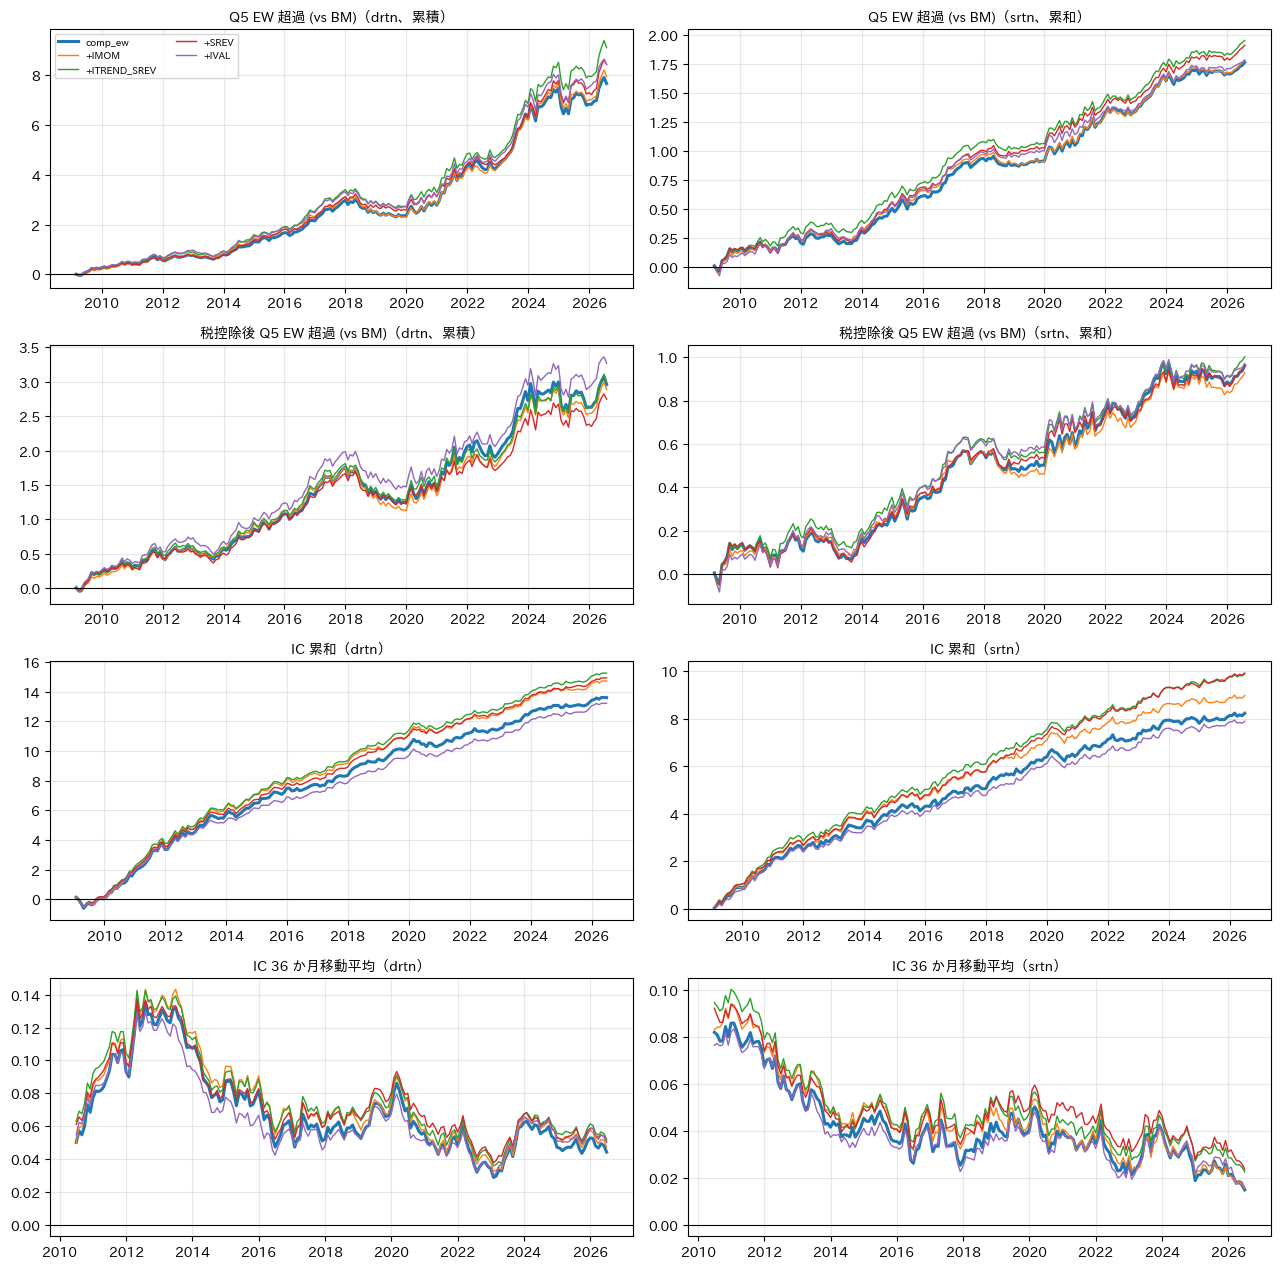

In [5]:
fig = plot_cumulative(
    {n: reports[n] for n in ["comp_ew", "+IMOM", "+ITREND_SREV", "+SREV", "+IVAL"]},
    metrics=("ew_excess", "after_tax_excess", "ic"),
    highlight=("comp_ew",),
)
plt.show()

## 3. 混合比率 $\lambda$ への感度

$\lambda = 0.1, 0.2, 0.3$ で、`comp_ew` との差（全期間、年率）と税控除後を見る。

In [6]:
rows = {}
for n in ["IMOM", "ITREND_SREV", "SREV", "IVAL"]:
    for lam in [0.1, 0.2, 0.3]:
        rep = (
            reports[f"+{n}"]
            if lam == LAMBDA
            else report(f"+{n} λ{lam}", overlay(signals[n], lam))
        )
        r = {}
        for metric, label, scale in [
            ("ew_excess", "Q5 超過", 12),
            ("ic", "IC", 1),
            ("spread", "Q5−Q1", 12),
            ("after_tax_excess", "税後 Q5", 12),
        ]:
            d = (
                rep.series[metric]["drtn"] - reports["comp_ew"].series[metric]["drtn"]
            ).dropna()
            r[(label, "差")] = d.mean() * scale
            r[(label, "t")] = tstat(d)
        r[("回転率", "EW")] = float(rep.turnover.mean()) * 12
        rows[(n, lam)] = r
display(pd.DataFrame(rows).T.round(3))

Q5 超過            IC         Q5−Q1         税後 Q5           回転率
                     差      t      差      t      差      t      差      t     EW
IMOM        0.1  0.005  1.346  0.003  3.588  0.013  2.336  0.003  0.921  4.091
            0.2  0.002  0.284  0.005  3.150  0.017  1.894 -0.001 -0.249  4.361
            0.3  0.008  1.016  0.007  2.489  0.021  1.825  0.001  0.075  4.770
ITREND_SREV 0.1  0.008  2.491  0.004  6.800  0.021  3.991  0.005  1.432  4.275
            0.2  0.009  1.602  0.008  5.770  0.034  3.886  0.000  0.069  4.856
            0.3  0.009  1.189  0.010  4.463  0.034  2.705 -0.005 -0.688  5.669
SREV        0.1  0.009  2.155  0.003  4.476  0.016  2.383  0.005  1.272  4.317
            0.2  0.005  0.779  0.006  3.647  0.021  1.965 -0.004 -0.612  4.952
            0.3 -0.003 -0.289  0.008  2.519  0.016  1.027 -0.016 -1.868  5.900
IVAL        0.1  0.003  0.910 -0.000 -0.229  0.007  1.213  0.003  0.745  4.052
            0.2  0.005  0.810 -0.002 -0.754  0.010  0.970  0.005  0.715  4.039
            0.3  0.003  0.346 -0.005 -1.267  0.005  0.310  0.004  0.433  3.950

## 4. バッファ付き分位で回転率を抑えたとき

1 か月のシグナルは回転率を上げ、税控除後の改善を相殺する。既存のバッファ付き分位（Q5 に入るのは上位 20%、
外れるのは上位 30% を割ったとき = バッファ 0.1）で、税控除後の改善が残るかを見る。

In [7]:
def report_buf(name: str, score: pd.DataFrame, buffer: float):
    return compute_alpha_report(
        name,
        score,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        buffer=buffer,
        cw_max_weight=CW_MAX_WEIGHT,
        tax_schedule=schedule,
        cost_buy=COST_BUY,
        cost_sell=COST_SELL,
        burn_in=BURN_IN,
        tax_kind="drtn",
    )


rows = {}
for buf in [0.0, 0.1]:
    base = reports["comp_ew"] if buf == 0.0 else report_buf("comp_ew", comp, buf)
    for n, lam in [
        ("comp_ew", None),
        ("ITREND_SREV", 0.1),
        ("ITREND_SREV", 0.2),
        ("SREV", 0.1),
    ]:
        if lam is None:
            rep = base
        elif buf == 0.0 and lam == LAMBDA:
            rep = reports[f"+{n}"]
        else:
            rep = report_buf(f"+{n} λ{lam}", overlay(signals[n], lam), buf)
        r = {
            "Q5 超過": rep.series["ew_excess"]["drtn"].mean() * 12,
            "税後 Q5": rep.series["after_tax_excess"]["drtn"].mean() * 12,
            "回転率 EW": float(rep.turnover.mean()) * 12,
        }
        if lam is not None:
            for metric, label in [
                ("ew_excess", "Q5 超過"),
                ("after_tax_excess", "税後 Q5"),
            ]:
                d = (rep.series[metric]["drtn"] - base.series[metric]["drtn"]).dropna()
                r[f"{label} 差"] = d.mean() * 12
                r[f"{label} 差 t"] = tstat(d)
                for p, (a, b) in {"IS": IS, "OOS": OOS}.items():
                    r[f"{label} 差 {p}"] = d.loc[a:b].mean() * 12
        rows[(f"バッファ {buf}", n if lam is None else f"+{n} λ{lam}")] = r
display(pd.DataFrame(rows).T.round(3))

Q5 超過  税後 Q5  回転率 EW  Q5 超過 差  Q5 超過 差 t  Q5 超過 差 IS  Q5 超過 差 OOS  税後 Q5 差  税後 Q5 差 t  税後 Q5 差 IS  税後 Q5 差 OOS
バッファ 0.0 comp_ew            0.130  0.085   4.022      NaN        NaN         NaN          NaN      NaN        NaN         NaN          NaN
         +ITREND_SREV λ0.1  0.139  0.089   4.275    0.008      2.491       0.006        0.011    0.005      1.432       0.003        0.007
         +ITREND_SREV λ0.2  0.139  0.085   4.856    0.009      1.602       0.012        0.006    0.000      0.069       0.002       -0.002
         +SREV λ0.1         0.139  0.090   4.317    0.009      2.155       0.006        0.011    0.005      1.272       0.004        0.006
バッファ 0.1 comp_ew            0.123  0.089   2.697      NaN        NaN         NaN          NaN      NaN        NaN         NaN          NaN
         +ITREND_SREV λ0.1  0.126  0.089   2.865    0.002      0.794      -0.002        0.007   -0.000     -0.022      -0.004        0.004
         +ITREND_SREV λ0.2  0.130  0.088   3.333    0.006      1.216      -0.002        0.014   -0.001     -0.198      -0.009        0.007
         +SREV λ0.1         0.126  0.088   2.920    0.002      0.642      -0.003        0.008   -0.001     -0.228      -0.006        0.005

## 5. 所見

**結論: 「業種で順張り × 銘柄で逆張り」（`ITREND_SREV`）は `comp_ew` とほぼ無相関で、加えると IC と Q5−Q1 は IS・OOS の両方で有意に上がる。
ただし 1 か月のシグナルなので回転率が上がり、ロングオンリーの税控除後ではほとんど残らない。バッファ付き分位で回転率を抑えると上乗せは消え、
`comp_ew` にバッファを付けるだけの方が税控除後は同等以上。セクターの割安度（`IVAL`）は頑健でない。**

1. **単体の成績**（Q5−Q1、IS = 2009〜2017 年 / OOS = 2018 年以降）:
   - `IMOM1`（業種の 1 か月モメンタム）: IS 14.1%（t 3.0）→ OOS 3.7%（t 0.9）。**OOS で弱まった**
   - `SREV`（銘柄の業種内 1 か月リバーサル）: IS 2.7%（t 0.6）→ OOS 9.3%（t 2.5）。**OOS で強まった**
   - `ITREND_SREV`（両者の等ウェイト）: IS 11.2%（t 3.7）、OOS 8.1%（t 2.2）。両期間で効くが、それぞれ別の時期に効いた 2 つを分散した結果で、片方ずつは頑健でない
   - `IMOM`（業種の 1 か月 + リビジョン）: IS t 3.5、OOS t 2.2。`IVAL`: IS t 0.6、OOS t 1.4。`VAL_RAW`: どちらも t < 0.5
   - `comp_ew` との順位相関はどれも −0.1〜0.1 で、新しい情報ではある
2. **`comp_ew` に 20% 加えたとき**: `+ITREND_SREV` は Q5 超過 13.0% → 13.9%、IC 0.065 → 0.073、Q5−Q1 17.6% → 21.0%（ICIR 0.48 → 0.56）。
   `comp_ew` との差は、IC が IS t 4.8 / OOS t 3.3、Q5−Q1 が IS t 3.2 / OOS t 2.2 で、両期間とも有意。Q5 超過の差は IS t 1.6 / OOS t 0.7 で有意でない。
3. **税控除後はほぼ残らない**: 回転率が年 4.0 → 4.9 倍、税ドラッグが 2.8% → 3.3% に増え、税控除後の Q5 超過は 8.5% で `comp_ew` と同じ。
   $\lambda = 0.1$ なら税控除後 +0.5%（t 1.4）残るが、有意ではない。
4. **バッファ付き分位（0.1）では上乗せが消える**: `comp_ew` 自体の税控除後が 8.5% → 8.9%（回転率 4.0 → 2.7 倍）に上がり、
   業種成分を加えた版の税控除後との差は −0.1〜0.0%。1 か月のシグナルの価値は、入替えを抑えると取れなくなる。
5. **セクターの割安度（`IVAL`）**: 加えると税控除後 +1.0%（IS）だが OOS は −0.1%。単体も IS t 0.6 で、01 の「BP は業種間で効く」は頑健な結果ではなかった。
6. **2018〜19 年の窓**: どの業種成分も構造的な負け（Q5 超過 −13〜−18%）は変えない。窓はシグナルではなくサイズの問題という 03 の結論と一致。

**含意**

- 業種の短期モメンタムと銘柄の短期リバーサルは、IC やロングショートでは確かな情報だが、インドのロングオンリー運用では回転率と STCG で相殺される。
  取りにいくなら、bax で回転率ペナルティをかけたうえで、リバランスで動かす銘柄の優先順位付け（タイブレーク）に使う形が現実的
- 業種成分の加算は、税控除後で見る限り `comp_ew` の改善策にならない。先に効くのはバッファなどの回転率の管理
